In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from glob import glob
from PIL import Image, ImageStat
import numpy as np


In [2]:
# Paths
base_path = "../data"
dataset_splits = ["train", "valid", "test"]


In [3]:
# Summary Containers
data_summary = []
all_image_stats = []

In [4]:
#Class distribution per split
for split in dataset_splits:
    split_path = os.path.join(base_path, split)
    class_dirs = [d for d in os.listdir(split_path) if os.path.isdir(os.path.join(split_path, d))]
    class_counts = {cls: len(os.listdir(os.path.join(split_path, cls))) for cls in class_dirs}
    for cls, count in class_counts.items():
        data_summary.append({"split": split, "class": cls, "count": count})

        # Additional: gather image quality stats from train split
        if split == "train":
            img_paths = glob(os.path.join(split_path, cls, "*.jpg"))
            for img_path in img_paths:
                img = Image.open(img_path).convert("RGB")
                stat = ImageStat.Stat(img)
                brightness = sum(stat.mean) / 3
                contrast = sum(stat.stddev) / 3
                width, height = img.size
                aspect_ratio = width / height
                all_image_stats.append({
                    "class": cls,
                    "path": img_path,
                    "brightness": brightness,
                    "contrast": contrast,
                    "aspect_ratio": aspect_ratio,
                    "width": width,
                    "height": height
                })


In [5]:
# Convert to DataFrame
summary_df = pd.DataFrame(data_summary)
image_stats_df = pd.DataFrame(all_image_stats)

In [6]:
print("\n📊 Class distribution per split:")
print(summary_df.pivot(index="class", columns="split", values="count").fillna(0).astype(int))


📊 Class distribution per split:
split                       test  train  valid
class                                         
ABBOTTS BABBLER                5    166      5
ABBOTTS BOOBY                  5    180      5
ABYSSINIAN GROUND HORNBILL     5    179      5
AFRICAN CROWNED CRANE          5    137      5
AFRICAN EMERALD CUCKOO         5    154      5
AFRICAN FIREFINCH              5    137      5
AFRICAN OYSTER CATCHER         5    155      5
AFRICAN PIED HORNBILL          5    187      5
AFRICAN PYGMY GOOSE            5    179      5
ALBATROSS                      5    133      5
ALBERTS TOWHEE                 5    161      5
ALEXANDRINE PARAKEET           5    165      5
ALPINE CHOUGH                  5    166      5
ALTAMIRA YELLOWTHROAT          5    150      5
AMERICAN AVOCET                5    179      5
AMERICAN BITTERN               5    170      5
AMERICAN COOT                  5    158      5
AMERICAN FLAMINGO              5    164      5
AMERICAN GOLDFINCH         

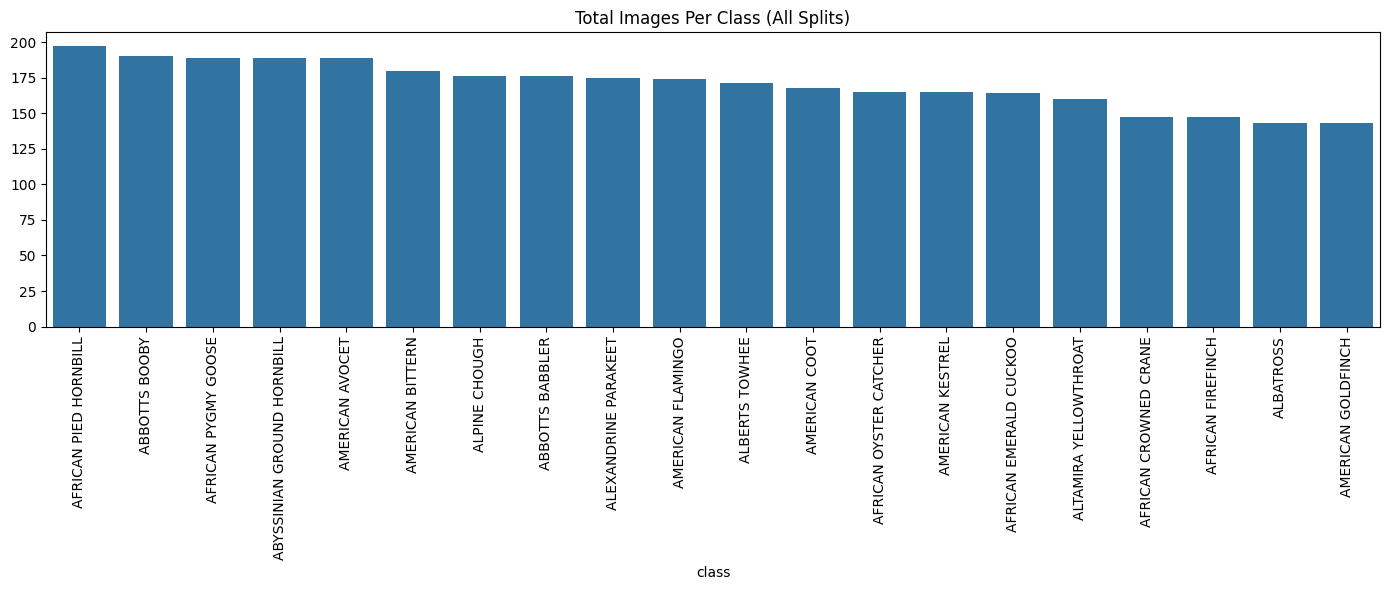

In [7]:
# 1️⃣ Class Imbalance Plot
class_totals = summary_df.groupby("class")["count"].sum().sort_values(ascending=False)
plt.figure(figsize=(14, 6))
sns.barplot(x=class_totals.index, y=class_totals.values)
plt.xticks(rotation=90)
plt.title("Total Images Per Class (All Splits)")
plt.tight_layout()
plt.savefig("eda_class_imbalance.png")
#plt.close()
plt.show()

In [8]:
# 2️⃣ Dataset Stats Summary
print("\n📋 Dataset Stats Summary:")
total_counts = summary_df.groupby("split")["count"].sum()
print(total_counts)


📋 Dataset Stats Summary:
split
test      100
train    3208
valid     100
Name: count, dtype: int64


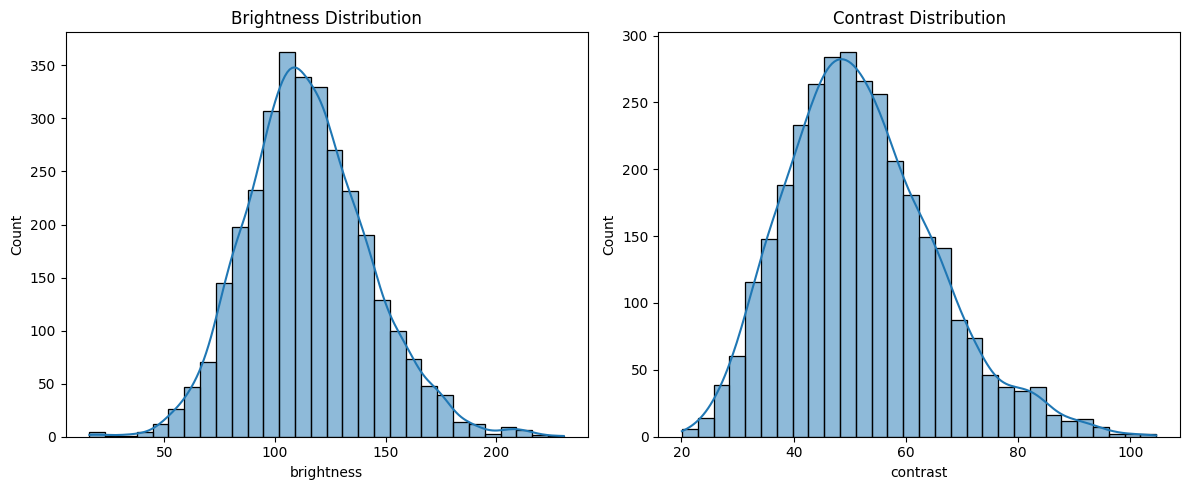

In [9]:
# 3️⃣ Brightness & Contrast Histograms
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(image_stats_df["brightness"], bins=30, kde=True)
plt.title("Brightness Distribution")
plt.subplot(1, 2, 2)
sns.histplot(image_stats_df["contrast"], bins=30, kde=True)
plt.title("Contrast Distribution")
plt.tight_layout()
plt.savefig("eda_brightness_contrast.png")
#plt.close()
plt.show()

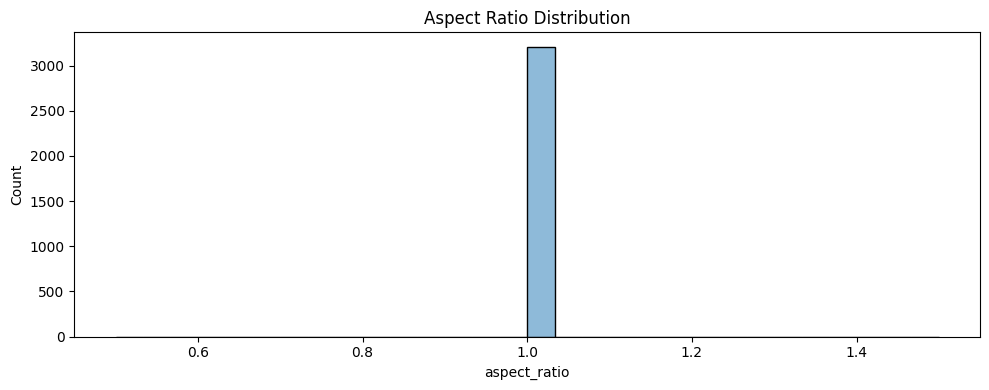

In [10]:
# 4️⃣ Aspect Ratio Distribution
plt.figure(figsize=(10, 4))
sns.histplot(image_stats_df["aspect_ratio"], bins=30, kde=True)
plt.title("Aspect Ratio Distribution")
plt.tight_layout()
plt.savefig("eda_aspect_ratio.png")
#plt.close()
plt.show()

In [11]:
# 5️⃣ Image Shape Counts
shape_counts = image_stats_df.groupby(["width", "height"]).size().reset_index(name="count")
print("\n📐 Image Dimensions Distribution:")
print(shape_counts.sort_values("count", ascending=False).head(10))



📐 Image Dimensions Distribution:
   width  height  count
0    224     224   3208



🔍 Saving sample images grid from 6 classes...


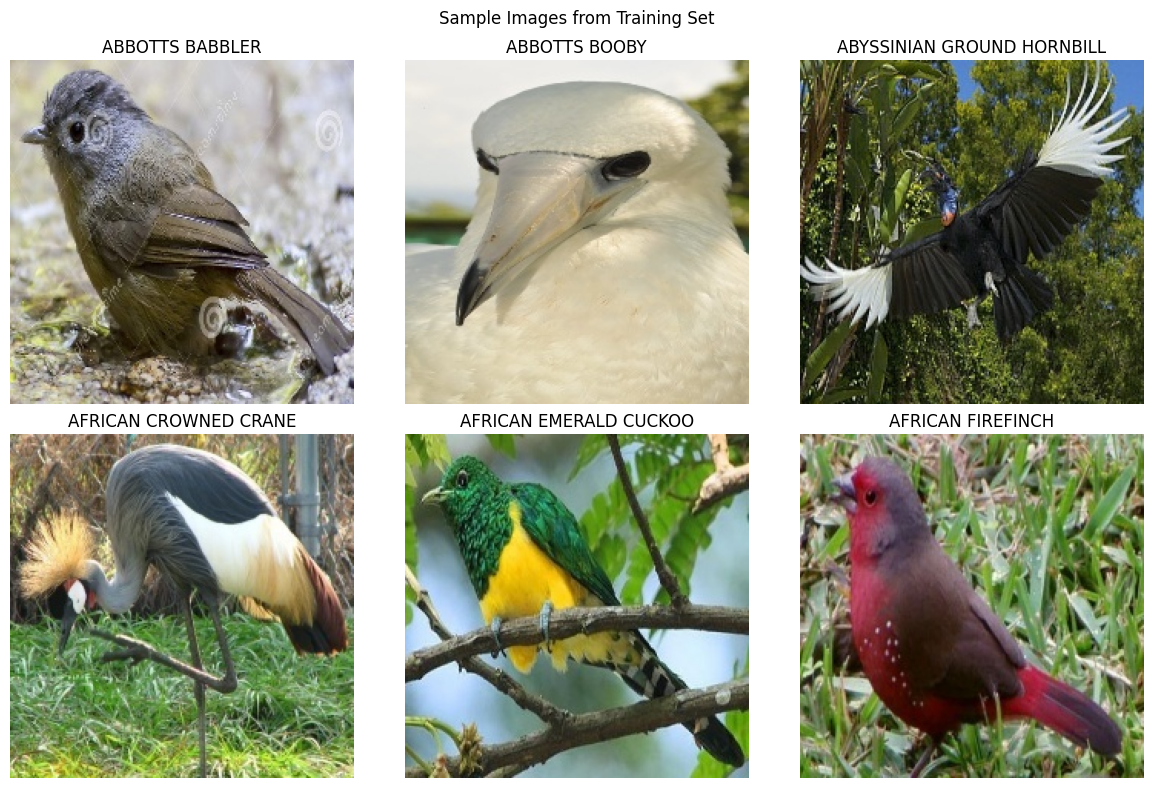

In [12]:
# Sample Images Grid
print("\n🔍 Saving sample images grid from 6 classes...")
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
classes_sample = summary_df["class"].unique()[:6]

for i, cls in enumerate(classes_sample):
    sample_img_path = glob(os.path.join(base_path, "train", cls, "*.jpg"))
    if sample_img_path:
        img = Image.open(sample_img_path[0]).convert("RGB")
        axes[i // 3, i % 3].imshow(img)
        axes[i // 3, i % 3].axis("off")
        axes[i // 3, i % 3].set_title(cls)
    else:
        axes[i // 3, i % 3].axis("off")
        axes[i // 3, i % 3].set_title(f"No Image - {cls}")

plt.suptitle("Sample Images from Training Set")
plt.tight_layout()
plt.savefig("eda_sample_images.png")
#plt.close()
plt.show()


In [13]:
print("\n✅ EDA completed. Outputs saved:")
print("- eda_class_distribution.png")
print("- eda_class_imbalance.png")
print("- eda_sample_images.png")
print("- eda_brightness_contrast.png")
print("- eda_aspect_ratio.png")


✅ EDA completed. Outputs saved:
- eda_class_distribution.png
- eda_class_imbalance.png
- eda_sample_images.png
- eda_brightness_contrast.png
- eda_aspect_ratio.png


## Additional Explorations for FSL Thesis Report

The cells below produce thesis-quality figures illustrating the dataset structure,
the base/novel class split, per-class statistics, and the N-Way K-Shot episode concept.

In [14]:
# Base / Novel class split (matches config)
BASE_CLASSES = [
    'ABBOTTS BABBLER', 'ABBOTTS BOOBY', 'ABYSSINIAN GROUND HORNBILL',
    'AFRICAN CROWNED CRANE', 'AFRICAN EMERALD CUCKOO', 'AFRICAN FIREFINCH',
    'AFRICAN OYSTER CATCHER', 'AFRICAN PIED HORNBILL', 'AFRICAN PYGMY GOOSE',
    'ALBATROSS', 'ALBERTS TOWHEE', 'ALEXANDRINE PARAKEET',
    'ALPINE CHOUGH', 'ALTAMIRA YELLOWTHROAT', 'AMERICAN AVOCET'
]
NOVEL_CLASSES = [
    'AMERICAN BITTERN', 'AMERICAN COOT', 'AMERICAN FLAMINGO',
    'AMERICAN GOLDFINCH', 'AMERICAN KESTREL'
]
print(f'Base classes  : {len(BASE_CLASSES)}')
print(f'Novel classes : {len(NOVEL_CLASSES)}')


Base classes  : 15
Novel classes : 5


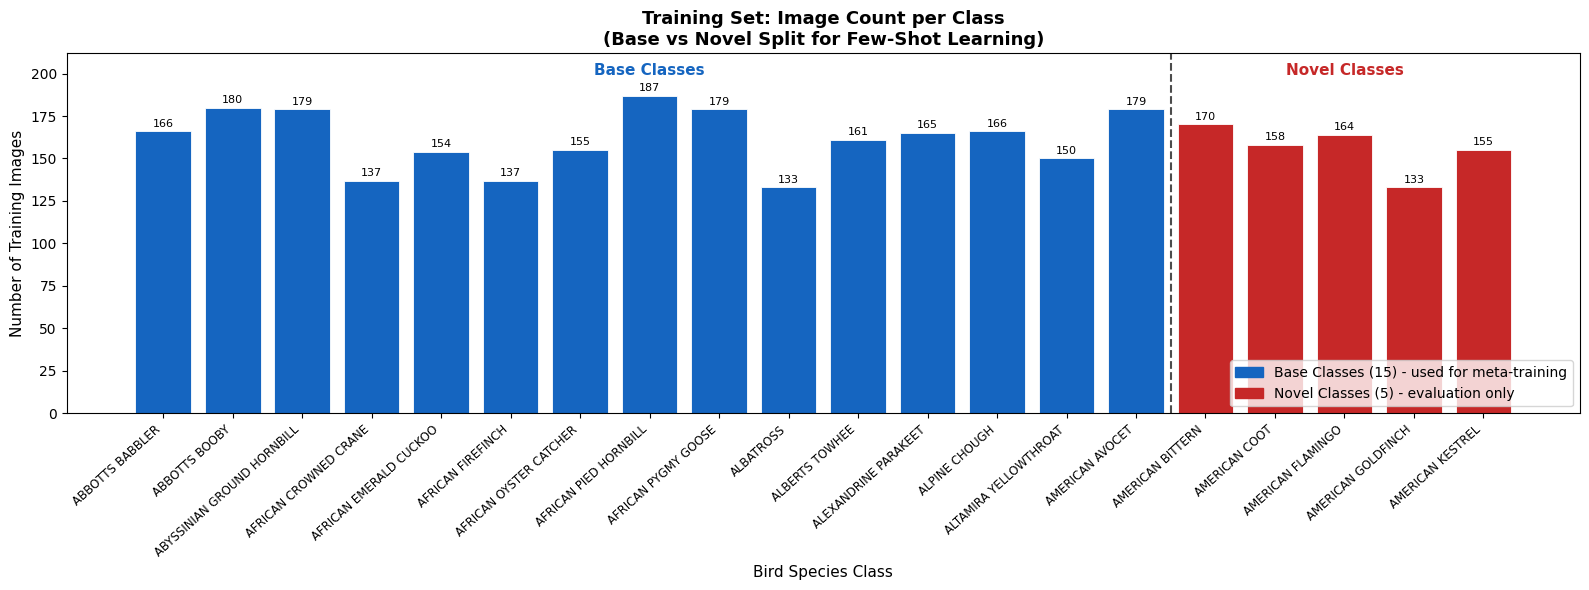

Saved: fsl_base_novel_train_counts.png


In [15]:
# Figure 1 - Training image count per class (base vs novel)
from matplotlib.patches import Patch

train_df = summary_df[summary_df['split'] == 'train'].copy()
train_df = train_df.sort_values('class').reset_index(drop=True)
train_df['role'] = train_df['class'].apply(
    lambda c: 'Base Classes (15)' if c in BASE_CLASSES else 'Novel Classes (5)')

BASE_COL, NOVEL_COL = '#1565C0', '#C62828'
bar_colors = [BASE_COL if r == 'Base Classes (15)' else NOVEL_COL for r in train_df['role']]

fig, ax = plt.subplots(figsize=(16, 6))
bars = ax.bar(range(len(train_df)), train_df['count'], color=bar_colors,
              edgecolor='white', linewidth=0.6)

for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
            str(int(bar.get_height())), ha='center', va='bottom', fontsize=8)

ax.set_xticks(range(len(train_df)))
ax.set_xticklabels(train_df['class'], rotation=42, ha='right', fontsize=8.5)
ax.axvline(x=14.5, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
ymax = max(train_df['count']) + 25
ax.text(7,   ymax * 0.94, 'Base Classes',   ha='center', fontsize=11, color=BASE_COL,  fontweight='bold')
ax.text(17,  ymax * 0.94, 'Novel Classes',  ha='center', fontsize=11, color=NOVEL_COL, fontweight='bold')
ax.legend(handles=[
    Patch(color=BASE_COL,  label='Base Classes (15) - used for meta-training'),
    Patch(color=NOVEL_COL, label='Novel Classes (5) - evaluation only')
], fontsize=10, loc='lower right')
ax.set_title('Training Set: Image Count per Class\n(Base vs Novel Split for Few-Shot Learning)',
             fontsize=13, fontweight='bold')
ax.set_ylabel('Number of Training Images', fontsize=11)
ax.set_xlabel('Bird Species Class', fontsize=11)
ax.set_ylim(0, ymax)
plt.tight_layout()
plt.savefig('fsl_base_novel_train_counts.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: fsl_base_novel_train_counts.png')


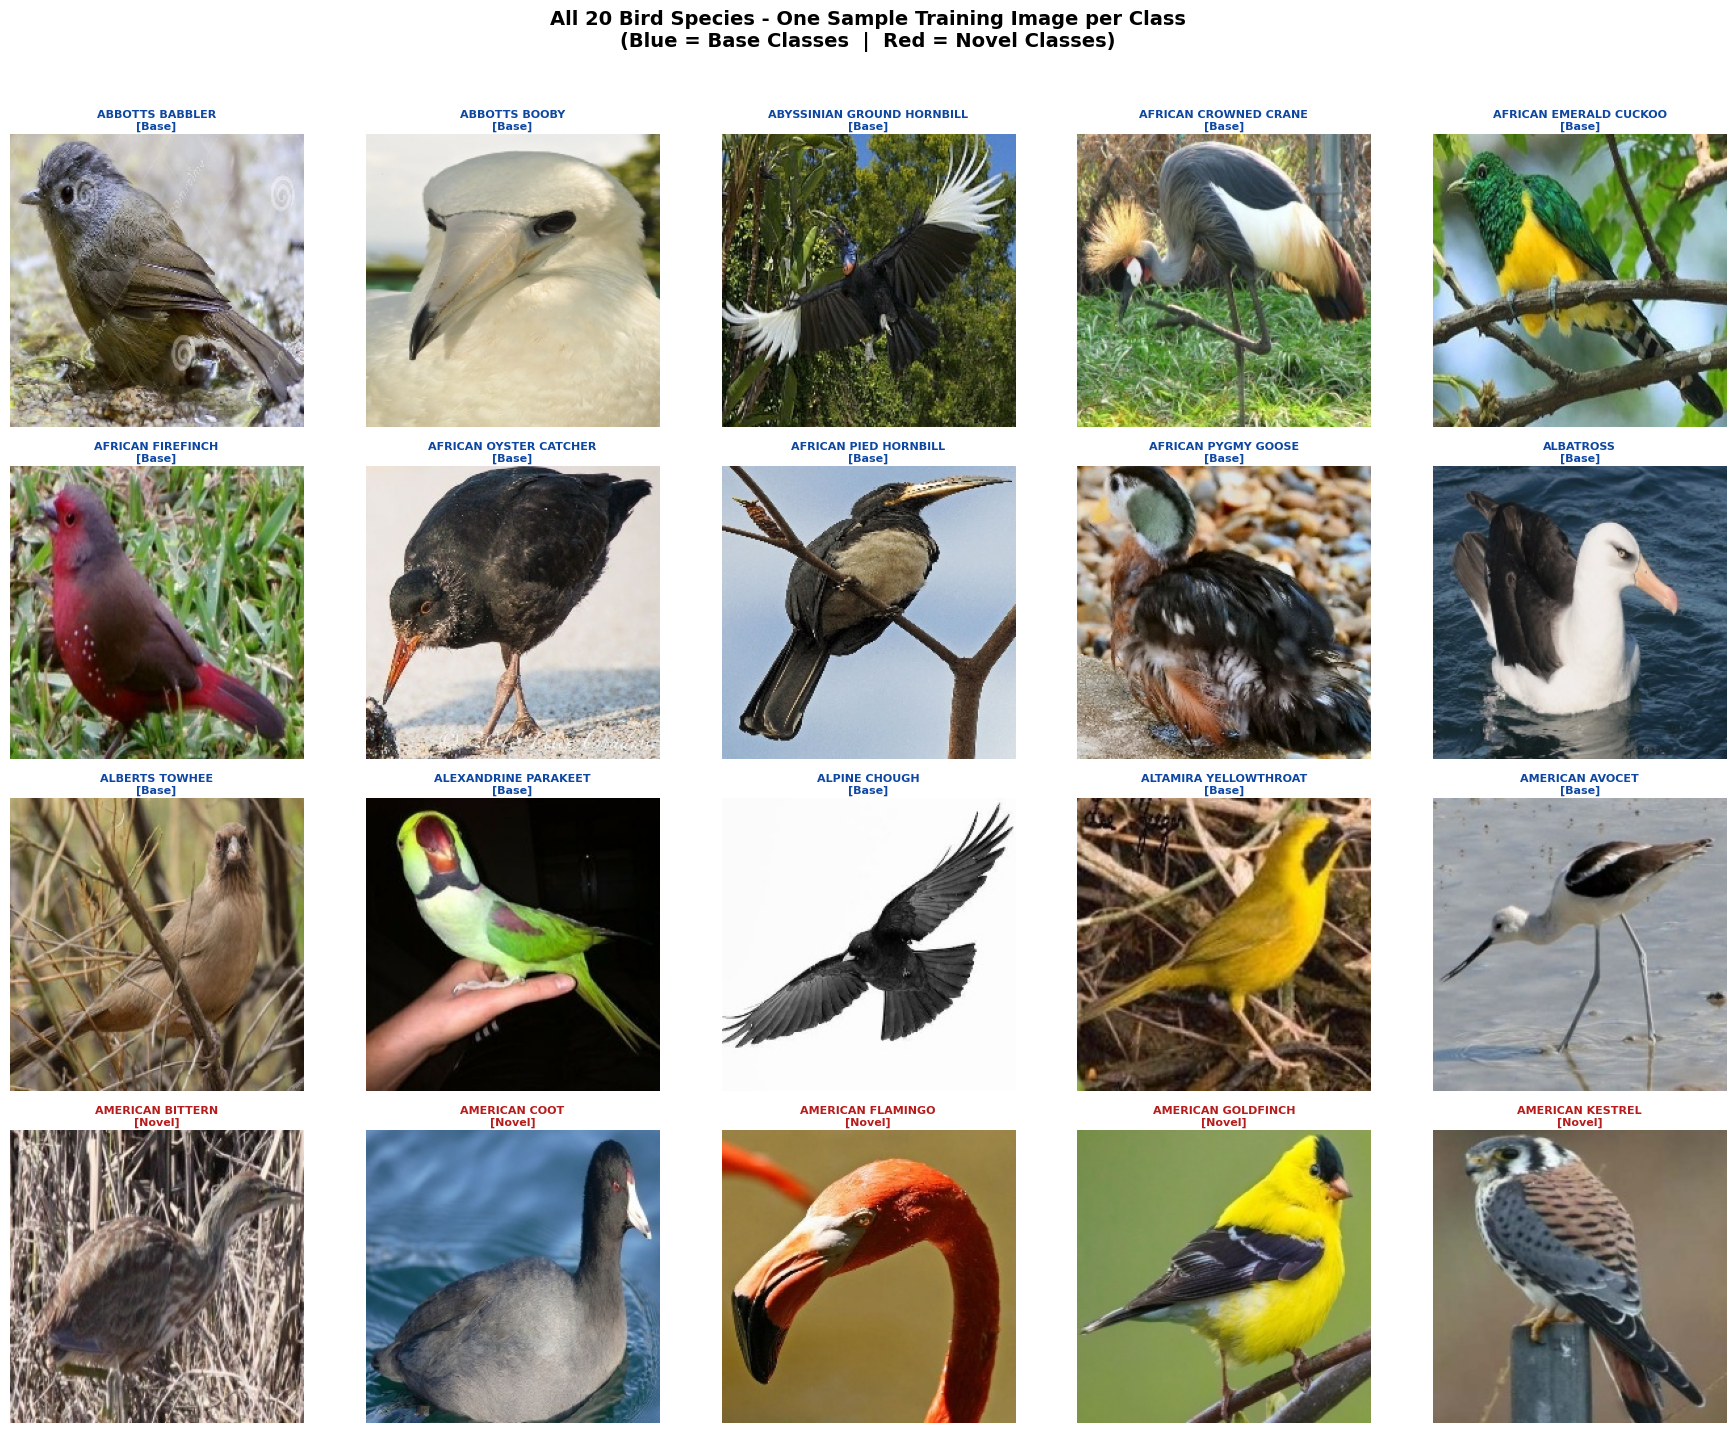

Saved: fsl_all_classes_sample_grid.png


In [16]:
# Figure 2 - Sample image from every class (4x5 grid, base/novel labelled)
all_classes = sorted(summary_df['class'].unique())
fig, axes = plt.subplots(4, 5, figsize=(18, 14))
axes = axes.flatten()

for i, cls in enumerate(all_classes):
    imgs = glob(os.path.join(base_path, 'train', cls, '*.jpg'))
    if imgs:
        img = Image.open(imgs[0]).convert('RGB')
        axes[i].imshow(img)
    axes[i].axis('off')
    role = 'Base' if cls in BASE_CLASSES else 'Novel'
    color = '#0D47A1' if role == 'Base' else '#B71C1C'
    axes[i].set_title(f'{cls}\n[{role}]', fontsize=8,
                      color=color, fontweight='bold', pad=3)

plt.suptitle(
    'All 20 Bird Species - One Sample Training Image per Class\n'
    '(Blue = Base Classes  |  Red = Novel Classes)',
    fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('fsl_all_classes_sample_grid.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: fsl_all_classes_sample_grid.png')


ipykernel_68712\4023555744.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=image_stats_df, x='class', y=metric, order=class_order,
ipykernel_68712\4023555744.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=image_stats_df, x='class', y=metric, order=class_order,
ipykernel_68712\4023555744.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(class_order, rotation=42, ha='right', fontsize=8.5)
ipykernel_68712\4023555744.py:27: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


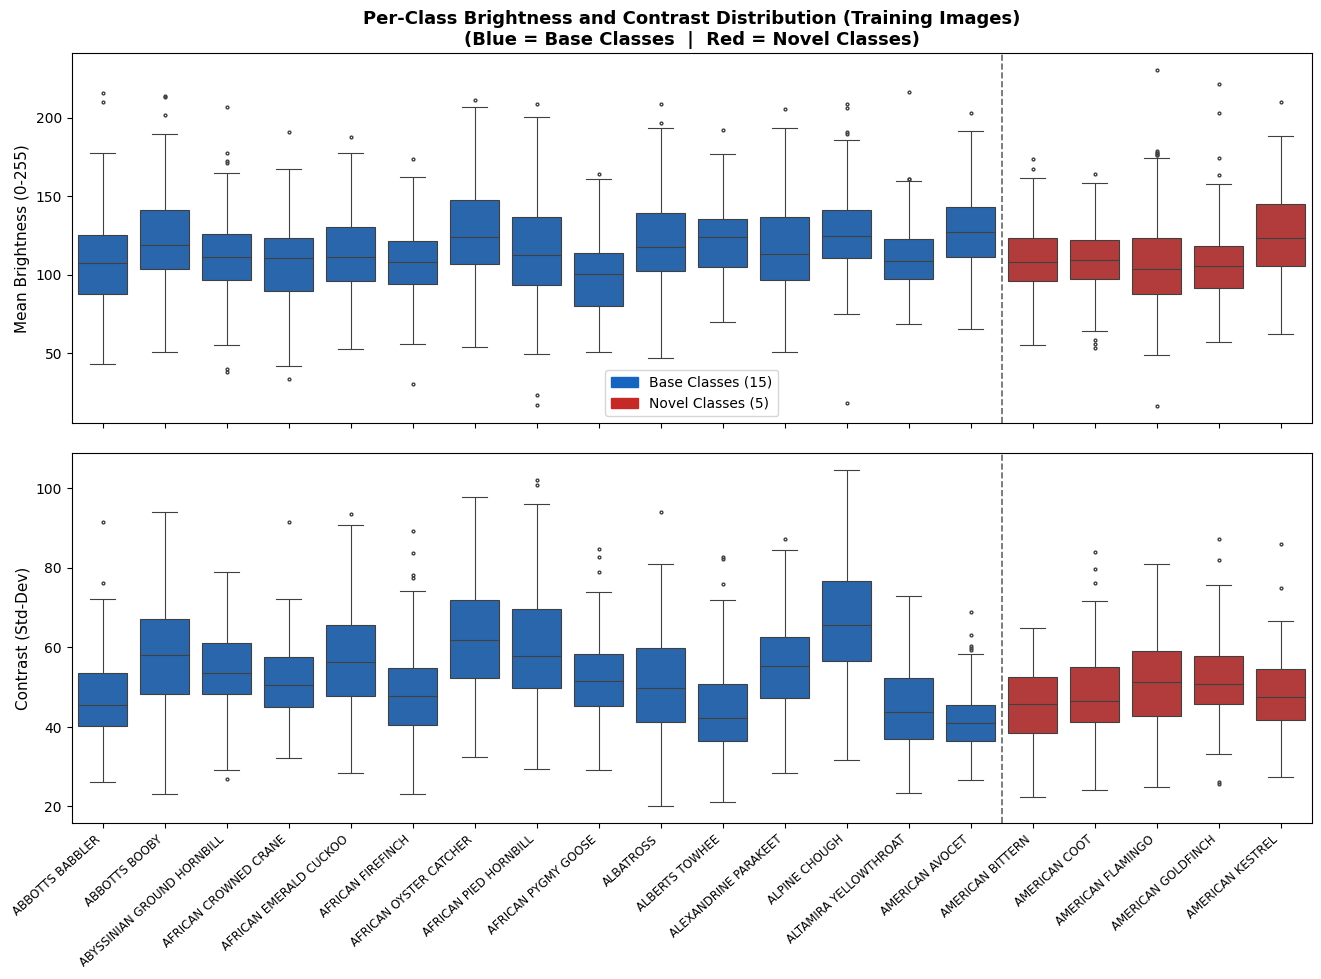

Saved: fsl_per_class_brightness_contrast.png


In [17]:
# Figure 3 - Per-class brightness and contrast distribution
from matplotlib.patches import Patch
class_order = sorted(image_stats_df['class'].unique())
role_palette = {cls: '#1565C0' if cls in BASE_CLASSES else '#C62828' for cls in class_order}

fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True,
                          gridspec_kw={'hspace': 0.08})

for ax, metric, label in zip(axes,
                               ['brightness', 'contrast'],
                               ['Mean Brightness (0-255)', 'Contrast (Std-Dev)']):
    sns.boxplot(data=image_stats_df, x='class', y=metric, order=class_order,
                palette=role_palette, ax=ax, fliersize=2, linewidth=0.8)
    ax.set_ylabel(label, fontsize=11)
    ax.set_xlabel('')
    ax.axvline(x=14.5, color='black', linestyle='--', linewidth=1.2, alpha=0.6)

axes[1].set_xticklabels(class_order, rotation=42, ha='right', fontsize=8.5)
axes[0].set_title(
    'Per-Class Brightness and Contrast Distribution (Training Images)\n'
    '(Blue = Base Classes  |  Red = Novel Classes)',
    fontsize=13, fontweight='bold')
axes[0].legend(handles=[
    Patch(color='#1565C0', label='Base Classes (15)'),
    Patch(color='#C62828', label='Novel Classes (5)')
], fontsize=10)
plt.tight_layout()
plt.savefig('fsl_per_class_brightness_contrast.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: fsl_per_class_brightness_contrast.png')


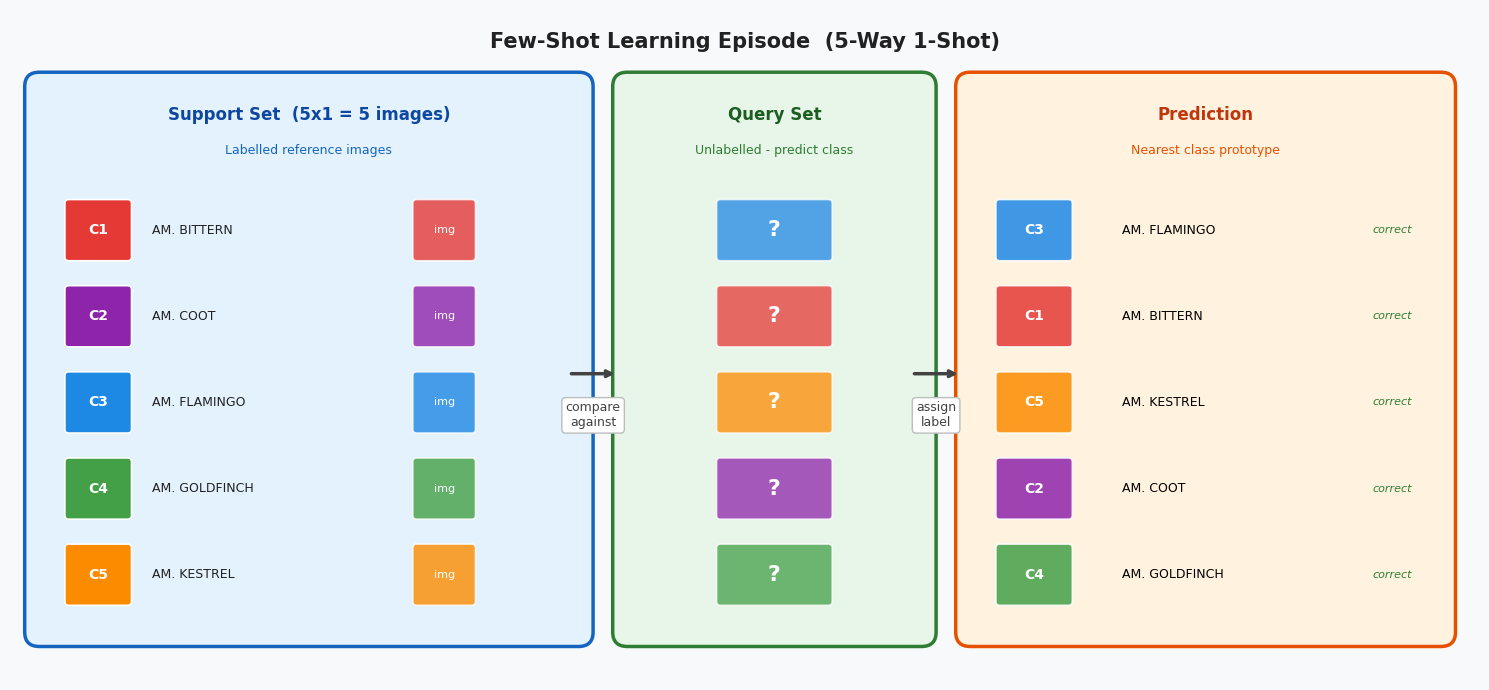

Saved: fsl_episode_concept.png


In [18]:
# Figure 4 - N-Way K-Shot Episode Concept (5-Way 1-Shot example)
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(15, 7))
ax.set_xlim(0, 15)
ax.set_ylim(0, 7)
ax.axis('off')
fig.patch.set_facecolor('#F8F9FA')

N_WAY, K_SHOT = 5, 1
cls_colors = ['#E53935', '#8E24AA', '#1E88E5', '#43A047', '#FB8C00']
sample_novel = NOVEL_CLASSES[:N_WAY]

ax.text(7.5, 6.6, f'Few-Shot Learning Episode  ({N_WAY}-Way {K_SHOT}-Shot)',
        ha='center', fontsize=15, fontweight='bold', color='#212121')

# Support Set box
ax.add_patch(mpatches.FancyBboxPatch((0.3, 0.5), 5.5, 5.7,
    boxstyle='round,pad=0.15', linewidth=2.5,
    edgecolor='#1565C0', facecolor='#E3F2FD'))
ax.text(3.05, 5.85, f'Support Set  ({N_WAY}x{K_SHOT} = {N_WAY*K_SHOT} images)',
        ha='center', fontsize=12, fontweight='bold', color='#0D47A1')
ax.text(3.05, 5.5, 'Labelled reference images', ha='center', fontsize=9, color='#1565C0')

for i, (cls, col) in enumerate(zip(sample_novel, cls_colors)):
    y = 4.7 - i * 0.9
    ax.add_patch(mpatches.FancyBboxPatch((0.6, y-0.28), 0.6, 0.56,
        boxstyle='round,pad=0.04', facecolor=col, edgecolor='white', linewidth=1.2))
    ax.text(0.9, y, f'C{i+1}', ha='center', va='center', fontsize=10, fontweight='bold', color='white')
    ax.text(1.45, y, cls.replace('AMERICAN ', 'AM. '), va='center', fontsize=9, color='#212121')
    ax.add_patch(mpatches.FancyBboxPatch((4.15, y-0.28), 0.56, 0.56,
        boxstyle='round,pad=0.04', facecolor=col, edgecolor='white', linewidth=1.2, alpha=0.8))
    ax.text(4.43, y, 'img', ha='center', va='center', fontsize=8, color='white')

# Query Set box
ax.add_patch(mpatches.FancyBboxPatch((6.3, 0.5), 3.0, 5.7,
    boxstyle='round,pad=0.15', linewidth=2.5,
    edgecolor='#2E7D32', facecolor='#E8F5E9'))
ax.text(7.8, 5.85, 'Query Set', ha='center', fontsize=12, fontweight='bold', color='#1B5E20')
ax.text(7.8, 5.5, 'Unlabelled - predict class', ha='center', fontsize=9, color='#2E7D32')
query_order = [2, 0, 4, 1, 3]
for idx, ci in enumerate(query_order):
    y = 4.7 - idx * 0.9
    ax.add_patch(mpatches.FancyBboxPatch((7.25, y-0.28), 1.1, 0.56,
        boxstyle='round,pad=0.04', facecolor=cls_colors[ci], edgecolor='white',
        linewidth=1.2, alpha=0.75))
    ax.text(7.8, y, '?', ha='center', va='center', fontsize=16, fontweight='bold', color='white')

# Prediction box
ax.add_patch(mpatches.FancyBboxPatch((9.8, 0.5), 4.8, 5.7,
    boxstyle='round,pad=0.15', linewidth=2.5,
    edgecolor='#E65100', facecolor='#FFF3E0'))
ax.text(12.2, 5.85, 'Prediction', ha='center', fontsize=12, fontweight='bold', color='#BF360C')
ax.text(12.2, 5.5, 'Nearest class prototype', ha='center', fontsize=9, color='#E65100')
for idx, ci in enumerate(query_order):
    y = 4.7 - idx * 0.9
    ax.add_patch(mpatches.FancyBboxPatch((10.1, y-0.28), 0.7, 0.56,
        boxstyle='round,pad=0.04', facecolor=cls_colors[ci], edgecolor='white',
        linewidth=1.2, alpha=0.85))
    ax.text(10.45, y, f'C{ci+1}', ha='center', va='center', fontsize=10, fontweight='bold', color='white')
    ax.text(11.35, y, sample_novel[ci].replace('AMERICAN ', 'AM. '), va='center', fontsize=9)
    ax.text(14.1, y, 'correct', ha='center', va='center', fontsize=8, color='#2E7D32', fontstyle='italic')

# Arrows
for x, lbl in [(5.95, 'compare\nagainst'), (9.45, 'assign\nlabel')]:
    ax.annotate('', xy=(x+0.25, 3.2), xytext=(x-0.25, 3.2),
                arrowprops=dict(arrowstyle='->', color='#424242', lw=2.5))
    ax.text(x, 2.65, lbl, ha='center', fontsize=9, color='#424242',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#BDBDBD'))

plt.tight_layout()
plt.savefig('fsl_episode_concept.png', dpi=150, bbox_inches='tight', facecolor='#F8F9FA')
plt.show()
print('Saved: fsl_episode_concept.png')


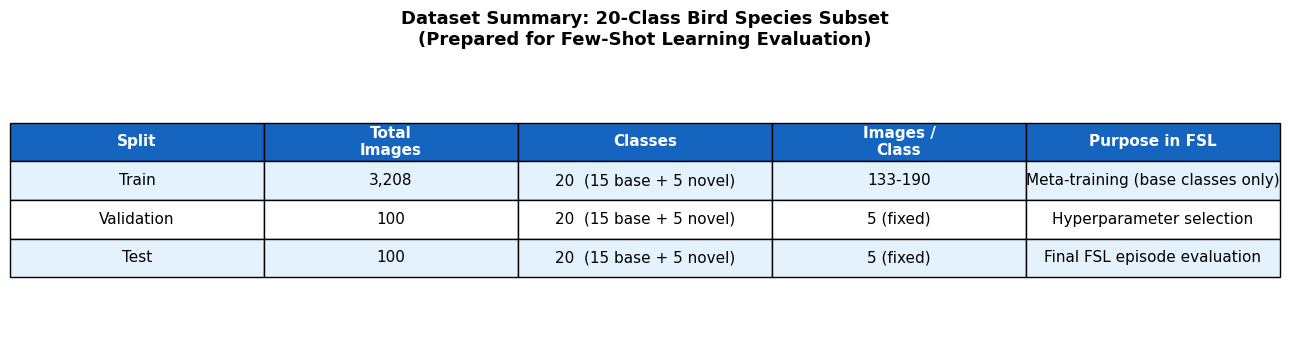

Saved: fsl_dataset_summary_table.png


In [19]:
# Figure 5 - Dataset summary table (thesis-ready)
fig, ax = plt.subplots(figsize=(13, 3.5))
ax.axis('off')

col_labels = ['Split', 'Total\nImages', 'Classes', 'Images /\nClass', 'Purpose in FSL']
cell_data = [
    ['Train',      '3,208', '20  (15 base + 5 novel)', '133-190',   'Meta-training (base classes only)'],
    ['Validation', '100',   '20  (15 base + 5 novel)', '5 (fixed)', 'Hyperparameter selection'],
    ['Test',       '100',   '20  (15 base + 5 novel)', '5 (fixed)', 'Final FSL episode evaluation'],
]

table = ax.table(cellText=cell_data, colLabels=col_labels, loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.0, 2.4)

HEADER_COL = '#1565C0'
for j in range(len(col_labels)):
    table[0, j].set_facecolor(HEADER_COL)
    table[0, j].set_text_props(color='white', fontweight='bold')
for i in range(len(cell_data)):
    for j in range(len(col_labels)):
        table[i+1, j].set_facecolor('#E3F2FD' if i % 2 == 0 else '#FFFFFF')

ax.set_title(
    'Dataset Summary: 20-Class Bird Species Subset\n'
    '(Prepared for Few-Shot Learning Evaluation)',
    fontsize=13, fontweight='bold', pad=18)
plt.tight_layout()
plt.savefig('fsl_dataset_summary_table.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: fsl_dataset_summary_table.png')


In [20]:
print('\n=== All EDA Figures Saved ===')
print('Original:')
print('  eda_class_imbalance.png')
print('  eda_brightness_contrast.png')
print('  eda_aspect_ratio.png')
print('  eda_sample_images.png')
print('New (thesis report figures):')
print('  fsl_base_novel_train_counts.png       Fig 1 - base/novel train counts')
print('  fsl_all_classes_sample_grid.png       Fig 2 - sample per class 4x5 grid')
print('  fsl_per_class_brightness_contrast.png Fig 3 - brightness/contrast boxplots')
print('  fsl_episode_concept.png               Fig 4 - N-Way K-Shot episode diagram')
print('  fsl_dataset_summary_table.png         Fig 5 - dataset summary table')



=== All EDA Figures Saved ===
Original:
  eda_class_imbalance.png
  eda_brightness_contrast.png
  eda_aspect_ratio.png
  eda_sample_images.png
New (thesis report figures):
  fsl_base_novel_train_counts.png       Fig 1 - base/novel train counts
  fsl_all_classes_sample_grid.png       Fig 2 - sample per class 4x5 grid
  fsl_per_class_brightness_contrast.png Fig 3 - brightness/contrast boxplots
  fsl_episode_concept.png               Fig 4 - N-Way K-Shot episode diagram
  fsl_dataset_summary_table.png         Fig 5 - dataset summary table
